In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

print("All libraries imported successfully!")
print("Scikit-learn version:", sklearn.__version__)

All libraries imported successfully!
Scikit-learn version: 1.9.1


In [5]:
# Create a sample customer dataset

data = {
    "Age": [22, 25, 30, 35, 40, 45, 50, 28, 32, 38,
            23, 27, 33, 42, 48, 52, 29, 36, 44, 55],
    
    "Annual_Income": [20000, 25000, 30000, 35000, 40000,
                      45000, 50000, 28000, 32000, 38000,
                      22000, 27000, 33000, 42000, 48000,
                      55000, 29000, 37000, 46000, 60000],
    
    "Purchase_Frequency": [2, 3, 4, 5, 6, 7, 8, 3, 4, 6,
                           2, 3, 5, 7, 8, 9, 4, 5, 7, 10],
    
    "Spending_Score": [20, 25, 30, 35, 45, 55, 70, 28, 38, 50,
                       22, 27, 40, 60, 72, 90, 32, 48, 65, 95]
}

df = pd.DataFrame(data)

print("Customer Dataset:")
display(df)

Customer Dataset:


,Age,Annual_Income,Purchase_Frequency,Spending_Score
0,22,20000,2,20
1,25,25000,3,25
2,30,30000,4,30
3,35,35000,5,35
4,40,40000,6,45
5,45,45000,7,55
6,50,50000,8,70
7,28,28000,3,28
8,32,32000,4,38
9,38,38000,6,50


In [6]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (20, 4)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Age                 20 non-null     int64
 1   Annual_Income       20 non-null     int64
 2   Purchase_Frequency  20 non-null     int64
 3   Spending_Score      20 non-null     int64
dtypes: int64(4)
memory usage: 772.0 bytes

Statistical Summary:


,Age,Annual_Income,Purchase_Frequency,Spending_Score
count,20.000000,20.00000,20.000000,20.000000
mean,36.700000,37100.00000,5.400000,47.350000
std,9.974177,11049.64872,2.326054,22.079462
min,22.000000,20000.00000,2.000000,20.000000
25%,28.750000,28750.00000,3.750000,29.500000
50%,35.500000,36000.00000,5.000000,42.500000
75%,44.250000,45250.00000,7.000000,61.250000
max,55.000000,60000.00000,10.000000,95.000000



Missing Values:
Age                   0
Annual_Income         0
Purchase_Frequency    0
Spending_Score        0
dtype: int64

Duplicate Rows: 0


In [7]:
# Check and remove duplicate records
df = df.drop_duplicates().copy()

# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Fill missing numerical values with column means
df = df.fillna(df.mean(numeric_only=True))

print("\nCleaned Dataset:")
display(df)

print("\nDataset Shape After Cleaning:", df.shape)
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
Age                   0
Annual_Income         0
Purchase_Frequency    0
Spending_Score        0
dtype: int64

Cleaned Dataset:


,Age,Annual_Income,Purchase_Frequency,Spending_Score
0,22,20000,2,20
1,25,25000,3,25
2,30,30000,4,30
3,35,35000,5,35
4,40,40000,6,45
5,45,45000,7,55
6,50,50000,8,70
7,28,28000,3,28
8,32,32000,4,38
9,38,38000,6,50



Dataset Shape After Cleaning: (20, 4)

Missing Values After Cleaning:
Age                   0
Annual_Income         0
Purchase_Frequency    0
Spending_Score        0
dtype: int64


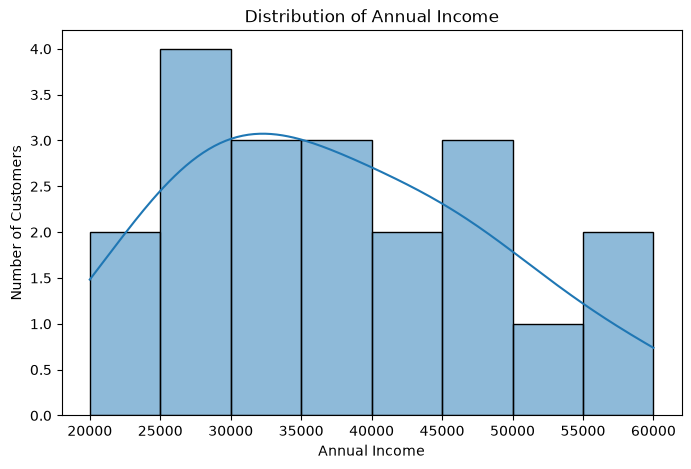

In [8]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Annual_Income", bins=8, kde=True)

plt.title("Distribution of Annual Income")
plt.xlabel("Annual Income")
plt.ylabel("Number of Customers")
plt.show()

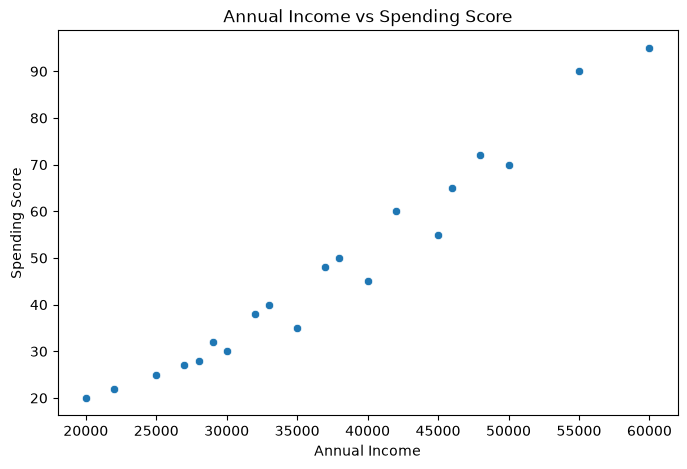

In [9]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Annual_Income",
    y="Spending_Score"
)

plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.show()

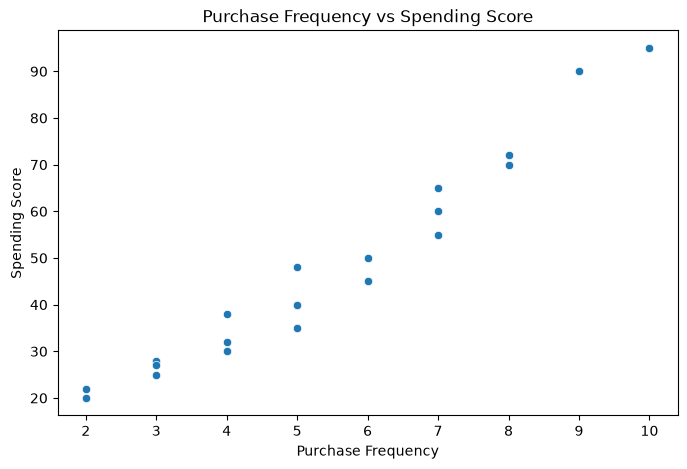

In [10]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Purchase_Frequency",
    y="Spending_Score"
)

plt.title("Purchase Frequency vs Spending Score")
plt.xlabel("Purchase Frequency")
plt.ylabel("Spending Score")
plt.show()

In [11]:
# Categorize customers based on their spending scores

def categorize_spending(score):
    if score < 40:
        return "Low"
    elif score < 70:
        return "Medium"
    else:
        return "High"

df["Spending_Category"] = df["Spending_Score"].apply(categorize_spending)

print("Customer Spending Categories:")
display(df[["Age", "Annual_Income", "Purchase_Frequency",
            "Spending_Score", "Spending_Category"]])

print("\nCategory Distribution:")
print(df["Spending_Category"].value_counts())

Customer Spending Categories:


,Age,Annual_Income,Purchase_Frequency,Spending_Score,Spending_Category
0,22,20000,2,20,Low
1,25,25000,3,25,Low
2,30,30000,4,30,Low
3,35,35000,5,35,Low
4,40,40000,6,45,Medium
5,45,45000,7,55,Medium
6,50,50000,8,70,High
7,28,28000,3,28,Low
8,32,32000,4,38,Low
9,38,38000,6,50,Medium



Category Distribution:
Spending_Category
Low       9
Medium    7
High      4
Name: count, dtype: int64


In [12]:
# Select input features and target

X = df[["Age", "Annual_Income", "Purchase_Frequency"]]
y = df["Spending_Category"]

print("Features (X):")
display(X.head())

print("\nTarget (y):")
display(y.head())

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)

Features (X):


,Age,Annual_Income,Purchase_Frequency
0,22,20000,2
1,25,25000,3
2,30,30000,4
3,35,35000,5
4,40,40000,6



Target (y):


0       Low
1       Low
2       Low
3       Low
4    Medium
Name: Spending_Category, dtype: str


Feature Shape: (20, 3)
Target Shape: (20,)


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 15
Testing samples: 5


In [14]:
# Import the machine learning model
from sklearn.tree import DecisionTreeClassifier

# Create the model
model = DecisionTreeClassifier(random_state=42)

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [15]:
# Predict spending categories for test data
y_pred = model.predict(X_test)

# Display actual and predicted results
results = pd.DataFrame({
    "Actual Category": y_test.values,
    "Predicted Category": y_pred
})

print("Customer Spending Predictions:")
display(results)

Customer Spending Predictions:


,Actual Category,Predicted Category
0,High,High
1,Medium,Medium
2,Low,Low
3,Medium,Low
4,Low,Low


In [16]:
from sklearn.metrics import accuracy_score, classification_report

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Model Accuracy: 80.0 %

Classification Report:
              precision    recall  f1-score   support

        High       1.00      1.00      1.00         1
         Low       0.67      1.00      0.80         2
      Medium       1.00      0.50      0.67         2

    accuracy                           0.80         5
   macro avg       0.89      0.83      0.82         5
weighted avg       0.87      0.80      0.79         5



In [17]:
# Create data for a new customer
new_customer = pd.DataFrame({
    "Age": [30],
    "Annual_Income": [40000],
    "Purchase_Frequency": [6]
})

# Predict spending category
prediction = model.predict(new_customer)

print("New Customer Details:")
display(new_customer)

print("Predicted Spending Category:", prediction[0])

New Customer Details:


,Age,Annual_Income,Purchase_Frequency
0,30,40000,6


Predicted Spending Category: Medium


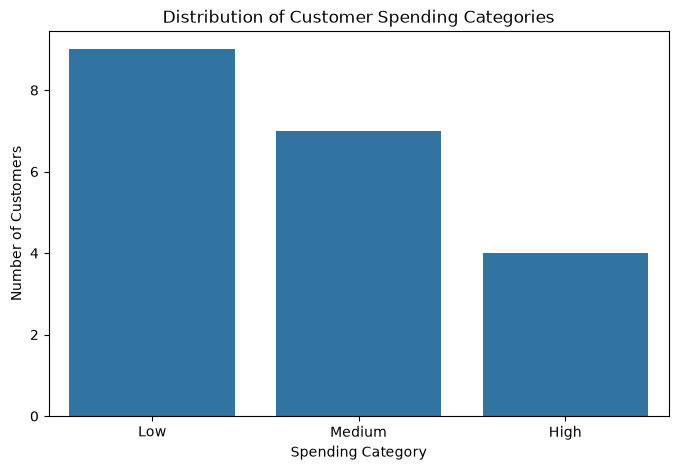

In [18]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Spending_Category",
    order=["Low", "Medium", "High"]
)

plt.title("Distribution of Customer Spending Categories")
plt.xlabel("Spending Category")
plt.ylabel("Number of Customers")
plt.show()

Feature Importance:


,Feature,Importance
1,Annual_Income,0.603873
2,Purchase_Frequency,0.396127
0,Age,0.000000


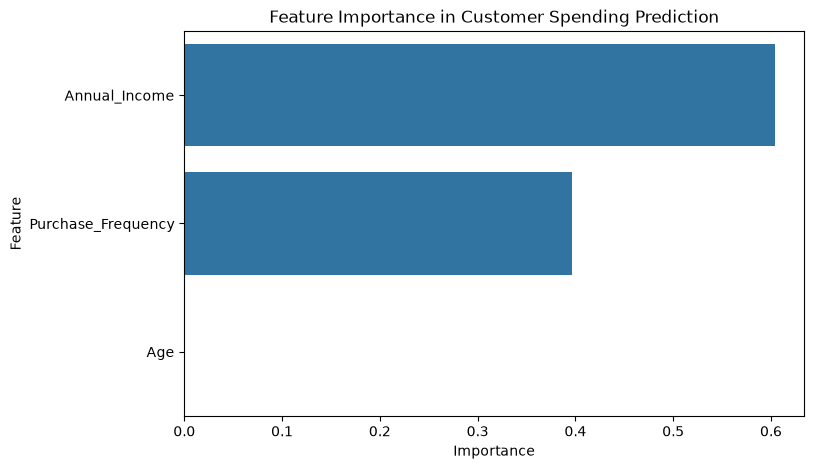

In [19]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("Feature Importance:")
display(feature_importance)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance in Customer Spending Prediction")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()